# IPO Listing Analysis & Gain Prediction

Exploratory Data Analysis & Pre Processing

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

db=pd.read_csv('/content/IPO_dataset - mainboard_ipos_2025_2026_filter.csv')
db.head(5)

,Company Name,IPO Year,IPO Open Date,IPO Close Date,Issue Price,Issue Size (Rs. Cr),GMP,GMP %,GMP date,QIB Subscription (x),NII Subscription (x),Retail Subscription (x),Total Subscription (x),Listing Price (NSE ₹)
0,Deepa Jewellers Ltd. [O],2026,01/09/2026,03/09/2026,177,459.72,23.00,12.99,07/09/2026,37.01,105.96,18.55,42.61,221.00
1,Rays of Belief Ltd. [O],2026,01/09/2026,03/09/2026,239,125.00,20.00,8.37,07/09/2026,9.06,279.11,195.87,107.71,239.00
2,Purple Style Labs Ltd. [CT],2026,31/08/2026,02/09/2026,575,680.00,-10.00,-1.74,07/09/2026,1.43,0.84,1.58,1.29,535.00
3,Priority Jewels Ltd. [P],2026,28/08/2026,01/09/2026,200,91.50,31.00,15.5,03/09/2026,39.87,166.49,106.76,100.45,230.00
4,ESDS Software Solution Ltd. [P],2026,28/08/2026,01/09/2026,429,720.00,255.00,59.44,02/09/2026,261.51,192.94,39.64,135.88,757.00


In [ ]:
db.shape

(393, 14)

In [ ]:
db.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 393 entries, 0 to 392
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Company Name             393 non-null    object 
 1   IPO Year                 393 non-null    int64  
 2   IPO Open Date            393 non-null    object 
 3   IPO Close Date           393 non-null    object 
 4   Issue Price              393 non-null    object 
 5   Issue Size (Rs. Cr)      393 non-null    object 
 6   GMP                      393 non-null    object 
 7   GMP %                    393 non-null    object 
 8   GMP date                 393 non-null    object 
 9   QIB Subscription (x)     393 non-null    float64
 10  NII Subscription (x)     393 non-null    float64
 11  Retail Subscription (x)  392 non-null    float64
 12  Total Subscription (x)   393 non-null    float64
 13  Listing Price (NSE ₹)    393 non-null    object 
dtypes: float64(4), int64(1), o

In [ ]:
db.columns

Index(['Company Name', 'IPO Year', 'IPO Open Date', 'IPO Close Date',
       'Issue Price', 'Issue Size (Rs. Cr)', 'GMP', 'GMP %', 'GMP date',
       'QIB Subscription (x)', 'NII Subscription (x)',
       'Retail Subscription (x)', 'Total Subscription (x)',
       'Listing Price (NSE ₹)'],
      dtype='object')

In [ ]:
db.describe()

,IPO Year,QIB Subscription (x),NII Subscription (x),Retail Subscription (x),Total Subscription (x)
count,393.000000,393.000000,393.000000,392.000000,393.000000
mean,2023.862595,73.585420,77.951552,21.984796,48.515929
std,1.651051,79.541292,118.841510,39.404835,58.163478
min,2020.000000,0.020000,0.050000,0.070000,0.200000
25%,2023.000000,4.130000,3.010000,2.045000,3.140000
50%,2024.000000,39.660000,32.240000,7.655000,25.980000
75%,2025.000000,136.850000,88.930000,23.792500,74.380000
max,2026.000000,420.570000,721.330000,374.800000,326.490000


In [ ]:
db.isnull().sum()

,0
Company Name,0
IPO Year,0
IPO Open Date,0
IPO Close Date,0
Issue Price,0
Issue Size (Rs. Cr),0
GMP,0
GMP %,0
GMP date,0
QIB Subscription (x),0


In [ ]:
db.duplicated().sum()

np.int64(0)

In [ ]:
db.columns=db.columns.str.strip().str.lower().str.replace(' ','_')

In [ ]:
date_cols=['ipo_open_date','ipo_close_date','gmp_date']
for col in date_cols:
  db[col]=pd.to_datetime(db[col],dayfirst=True,errors='coerce')

num_cols=['issue_price','listing_price_(nse_₹)','issue_size_(rs._cr)','gmp','gmp_%']
for cols in num_cols:
  # Convert to string, remove commas, handle double dots, and replace Unicode minus signs
  db[cols] = (db[cols].astype(str)
              .str.replace(',', '', regex=False)
              .str.replace('..', '.', regex=False)
              .str.replace('−', '-', regex=False)
              .astype('Float64'))
db.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 393 entries, 0 to 392
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   company_name             393 non-null    object        
 1   ipo_year                 393 non-null    int64         
 2   ipo_open_date            393 non-null    datetime64[ns]
 3   ipo_close_date           393 non-null    datetime64[ns]
 4   issue_price              393 non-null    Float64       
 5   issue_size_(rs._cr)      393 non-null    Float64       
 6   gmp                      393 non-null    Float64       
 7   gmp_%                    393 non-null    Float64       
 8   gmp_date                 393 non-null    datetime64[ns]
 9   qib_subscription_(x)     393 non-null    float64       
 10  nii_subscription_(x)     393 non-null    float64       
 11  retail_subscription_(x)  392 non-null    float64       
 12  total_subscription_(x)   393 non-nul

Feature Engineering

In [ ]:
db['listing_gain_%']=((db['listing_price_(nse_₹)']-db['issue_price'])/db['issue_price'])* 100         #target variable
db['listing_gain_%']

,listing_gain_%
0,24.858757
1,0.0
2,-6.956522
3,15.0
4,76.456876
...,...
388,87.5
389,13.4
390,-5.757576
391,-9.747292


In [ ]:
db['positive_listing'] = (db['listing_gain_%'] > 0).astype(int)  #classification target
db['positive_listing']

,positive_listing
0,1
1,0
2,0
3,1
4,1
...,...
388,1
389,1
390,0
391,0


In [ ]:
db['ipo_month'] = db['ipo_open_date'].dt.month
db['ipo_month']

,ipo_month
0,9
1,9
2,8
3,8
4,8
...,...
388,12
389,11
390,10
391,9


In [ ]:
#db['issue_size_log'] = np.log1p(db['issue_size_(rs._cr)'])
#db['issue_size_log']

# correlation

In [ ]:
corr = db.select_dtypes(include='number').corr()

corr['listing_gain_%'].sort_values(ascending=False)

,listing_gain_%
listing_gain_%,1.000000
total_subscription_(x),0.601472
qib_subscription_(x),0.562793
positive_listing,0.496101
nii_subscription_(x),0.452775
retail_subscription_(x),0.402694
listing_price_(nse_₹),0.263625
gmp_%,0.178277
gmp,0.148132
ipo_month,0.068057


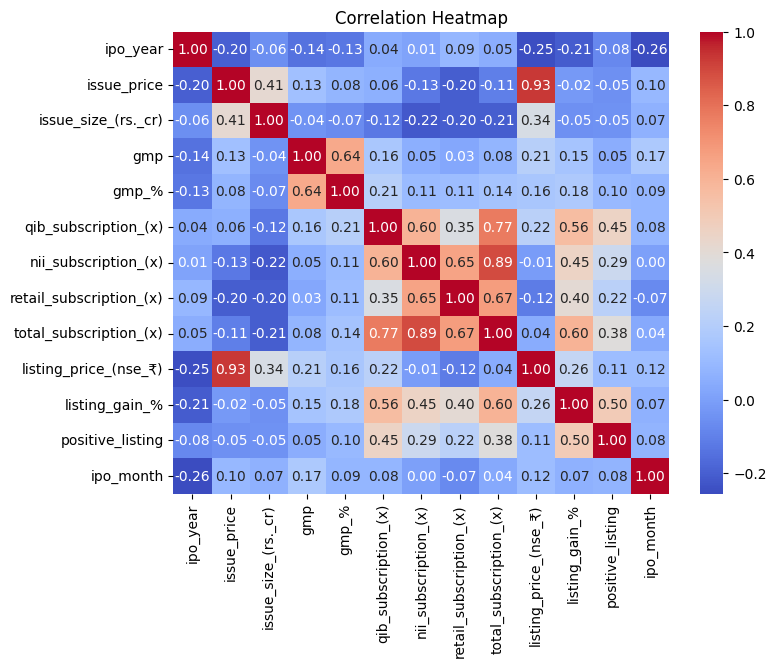

In [ ]:
plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

# ML Modeling

In [ ]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
features = [
    'issue_price',
    'issue_size_(rs._cr)',
    'gmp',
    'qib_subscription_(x)',
    'total_subscription_(x)'
]

X = db[features]
y = db['listing_gain_%']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (393, 5)
y shape: (393,)


**Linear Regression**

In [ ]:
def evaluate_model(model, X_train, X_test, y_train, y_test):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    print(f"MAE: {mae:.2f}")
    print(f"MSE: {mse:.2f}")
    print(f"RMSE: {rmse:.2f}")
    print(f"R²: {r2:.2f}")

    return mae, mse, rmse, r2

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42)

lr = LinearRegression()

lr_results = evaluate_model(
    lr, X_train, X_test, y_train, y_test
)

MAE: 18.43
MSE: 795.67
RMSE: 28.21
R²: 0.30


**Decision Tree**

In [ ]:
dt = DecisionTreeRegressor(random_state=42,max_depth=5)

dt_results = evaluate_model(
    dt, X_train, X_test, y_train, y_test
)

MAE: 19.43
MSE: 868.76
RMSE: 29.47
R²: 0.23


**Random Forest**

In [ ]:
rf = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    max_depth=5
)

rf_results = evaluate_model(
    rf, X_train, X_test, y_train, y_test
)

MAE: 17.28
MSE: 715.96
RMSE: 26.76
R²: 0.37


**XGBoost**

In [ ]:
xgb= XGBRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)
xgb_results = evaluate_model(
    xgb, X_train, X_test, y_train, y_test)

MAE: 19.12
MSE: 873.73
RMSE: 29.56
R²: 0.23


Hyperparameter Tuning in Random forest

---



In [ ]:

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7, 10],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}
rf = RandomForestRegressor(
    random_state=42
)
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=RandomForestRegressor(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [3, 5, 7, 10],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [100, 200, 300]},
             scoring='neg_mean_absolute_error')

In [ ]:
best_rf = grid_search.best_estimator_

tuned_rf_results = evaluate_model(
    best_rf,
    X_train,
    X_test,
    y_train,
    y_test
)

tuned_rf_results

MAE: 16.99
MSE: 700.78
RMSE: 26.47
R²: 0.38


(16.98901674625607,
 700.7761980586597,
 np.float64(26.472177811027557),
 0.38115632898652263)

Feature Importance

In [ ]:
feature_importance = pd.DataFrame({
    'Feature': features,
    'Importance': best_rf.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

feature_importance

,Feature,Importance
3,qib_subscription_(x),0.443407
4,total_subscription_(x),0.322664
1,issue_size_(rs._cr),0.145755
2,gmp,0.068006
0,issue_price,0.020168


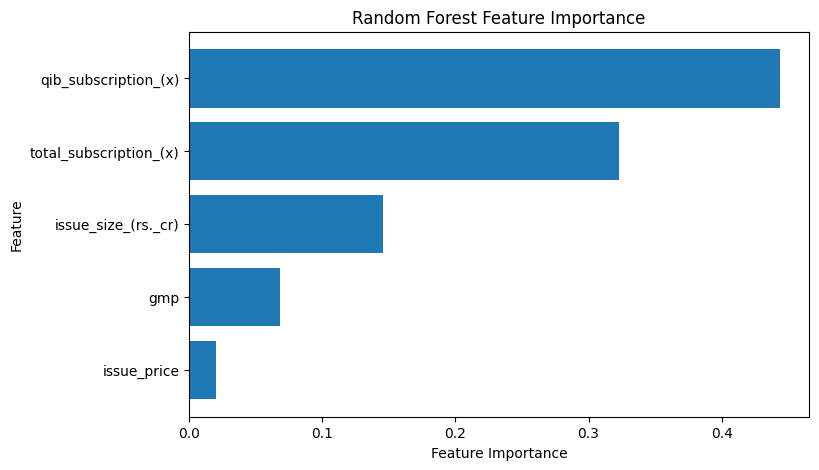

In [ ]:
plt.figure(figsize=(8, 5))

plt.barh(
    feature_importance['Feature'],
    feature_importance['Importance']
)

plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Random Forest Feature Importance')

plt.gca().invert_yaxis()
plt.show()

# Comparision

In [ ]:
results = pd.DataFrame(
    [lr_results, dt_results, rf_results, xgb_results, tuned_rf_results],
    columns=['MAE', 'MSE', 'RMSE', 'R²'],
    index=[
        'Linear Regression',
        'Decision Tree',
        'Random Forest',
        'XGBoost',
        'Tuned Random Forest'
    ]
)

results

,MAE,MSE,RMSE,R²
Linear Regression,18.425020,795.670387,28.207630,0.297357
Decision Tree,19.432826,868.755319,29.474656,0.232817
Random Forest,17.275634,715.964616,26.757515,0.367744
XGBoost,19.124044,873.731873,29.558956,0.228422
Tuned Random Forest,16.989017,700.776198,26.472178,0.381156


# Classification
Gain - NO Gain- Loss

In [ ]:
db['listing_category'] = np.select(
    [
        db['listing_gain_%'] > 0,
        db['listing_gain_%'] == 0,
        db['listing_gain_%'] < 0
    ],
    [
        'Gain',
        'No Gain',
        'Loss'
    ],
    default='Unknown'
)
db['listing_category'].value_counts()

,count
listing_category,
Gain,274
Loss,77
No Gain,42


In [ ]:
features = [
    'issue_price',
    'issue_size_(rs._cr)',
    'gmp',
    'qib_subscription_(x)',
    'total_subscription_(x)'
]

X_class = db[features]
y_class = db['listing_category']

In [ ]:
X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(
    X_class,
    y_class,
    test_size=0.20,
    random_state=42,
    stratify=y_class
)

**Random Forest Classifier**

In [ ]:
from sklearn.ensemble import RandomForestClassifier
rf_classifier = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf_classifier.fit(X_train_class, y_train_class)

y_pred_class = rf_classifier.predict(X_test_class)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

accuracy = accuracy_score(y_test_class, y_pred_class)

print(f"Accuracy: {accuracy:.2f}")
print("\nClassification Report:")
print(classification_report(y_test_class, y_pred_class))

Accuracy: 0.68

Classification Report:
              precision    recall  f1-score   support

        Gain       0.74      0.89      0.81        55
        Loss       0.42      0.31      0.36        16
     No Gain       0.00      0.00      0.00         8

    accuracy                           0.68        79
   macro avg       0.39      0.40      0.39        79
weighted avg       0.60      0.68      0.64        79



In [ ]:
cm = confusion_matrix(
    y_test_class,
    y_pred_class,
    labels=['Gain', 'Loss', 'No Gain']
)

print(cm)

[[49  5  1]
 [11  5  0]
 [ 6  2  0]]


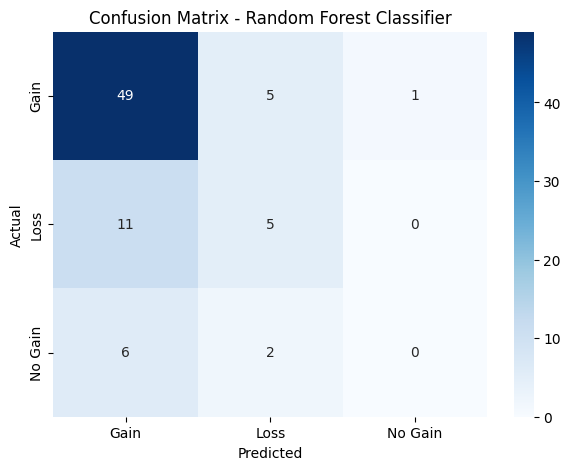

In [ ]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Gain', 'Loss', 'No Gain'],
    yticklabels=['Gain', 'Loss', 'No Gain']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Random Forest Classifier')
plt.show()

Testing with real IPO values

In [ ]:
new_ipo = pd.DataFrame({
    'issue_price': [424],
    'issue_size_(rs._cr)': [500],
    'gmp': [160],
    'qib_subscription_(x)': [203.61],
    'total_subscription_(x)': [103.01]
})

In [ ]:
# SS Retail named Ipo - listed gain- +47.17%

predicted_gain = best_rf.predict(new_ipo)[0]
predicted_category = rf_classifier.predict(new_ipo)[0]

print("IPO Prediction")
print("-------------------------")
print(f"Predicted Listing Gain: {predicted_gain:.2f}%")
print(f"Predicted Category: {predicted_category}")

IPO Prediction
-------------------------
Predicted Listing Gain: 47.22%
Predicted Category: Gain


In [ ]:
db.to_csv("IPO_Final_Dataset.xlsx", index=False)

# Key Findings

* QIB subscription was the most influential feature in the Random Forest
model, contributing approximately 44.3% of the model's feature importance.

* Total subscription was the second most influential feature, with approximately 32.3% importance.

* Issue size contributed approximately 14.6%.

* GMP contributed approximately 6.8%.

* Issue price had the lowest feature importance at approximately 2.0%.

* The tuned Random Forest improved upon the baseline Random Forest, reducing MAE from 17.82 to 16.99 and increasing R² from 0.32 to 0.38.

* The classification model achieved 68% overall accuracy for predicting Gain, Loss, and No Gain categories.

* The classification model performed substantially better for Gain IPOs than for the smaller Loss and No Gain groups.





# Project Outcome
* In this project, I developed a machine learning approach for predicting IPO listing gains using information available before listing.

*  The analysis showed that IPO subscription activity, particularly QIB and total subscription, played an important role in the model's predictions. GMP, issue size, and issue price also contributed, although to different degrees.

*  The final regression model was able to capture useful patterns in historical IPO data, but its performance also showed that IPO listing gains are influenced by factors beyond the five variables used in this project.

*  The classification analysis further demonstrated that predicting the broad outcome of an IPO is more difficult for the smaller Loss and No Gain categories, partly because the dataset contained fewer examples of these outcomes.

*  Overall, the project demonstrates how historical IPO data can be cleaned, analyzed, and used to build machine learning models for pre-listing prediction and decision-support analysis.

# Limitations & Future Scope



*   **Limitations**
    
   1. The final dataset contained 393 usable IPO records from 2026-2016, which limited the amount of historical information available for model training.
   2. The Loss and No Gain categories had fewer observations than the Gain category, affecting classification performance.
   3. The model used only five pre-listing features, so other factors that may influence listing performance were not included.
   4. IPO market conditions can change over time, which may affect how well historical patterns generalize to future IPOs.
   5. The model should therefore be treated as an analytical prediction tool rather than a guaranteed indicator of future listing performance.

*   **Future Scope**

    The project could be extended by:
    1. Adding more historical IPO records.
    2. Including additional pre-listing variables such as market conditions, anchor investor information, promoter details, and sector-level indicators.
    3. Testing additional machine learning algorithms and feature-engineering approaches.
    4. Using a larger and more balanced dataset for multi-class classification.
    5. Continuously updating the dataset as new IPOs are listed.


# Conclusion

This project explored whether pre-listing IPO information can be used to predict listing gains. The analysis identified subscription activity, particularly QIB and total subscription, as important model features. The final Tuned Random Forest achieved an R² of 0.38 for listing-gain prediction and the classification model achieved 68% accuracy across Gain, Loss, and No Gain categories.

While the results demonstrate useful predictive patterns, the limited dataset and minority-class imbalance highlight the challenges of predicting IPO outcomes. The project provides a foundation that can be improved through a larger dataset and additional pre-listing variables.

